### Import libraries

In [2]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 10.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from lightgbm import LGBMClassifier

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import joblib

### load the existing train/test split

In [7]:
data_dir = Path("../models")

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(data_dir / "y_train.csv").iloc[:, 0]
y_test = pd.read_csv(data_dir / "y_test.csv").iloc[:, 0]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts())

Training features: (5634, 8)
Testing features: (1409, 8)
Training target distribution:
churn_target
0    4139
1    1495
Name: count, dtype: int64


### Identify categorical and numerical columns

In [9]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

Categorical features: []
Numerical features: ['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']


### Build the LightGBM pipeline

In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            "passthrough",
            numerical_cols
        )
    ]
)

lightgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LGBMClassifier(
                objective="binary",
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=31,
                random_state=42,
                verbosity=-1
            )
        )
    ]
)

print("LightGBM pipeline created.")

LightGBM pipeline created.


### Train LightGBM

In [14]:
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "4"

In [15]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores.*",
    category=UserWarning
)

In [16]:
lightgbm_pipeline.fit(X_train, y_train)

print("LightGBM training completed.")

LightGBM training completed.


### Evaluate model performance

In [17]:
y_pred = lightgbm_pipeline.predict(X_test)
y_prob = lightgbm_pipeline.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print(
    "PR-AUC (Average Precision):",
    round(average_precision_score(y_test, y_prob), 4)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ROC-AUC: 0.7898
PR-AUC (Average Precision): 0.5679

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85      1035
           1       0.59      0.44      0.50       374

    accuracy                           0.77      1409
   macro avg       0.70      0.66      0.68      1409
weighted avg       0.75      0.77      0.76      1409



### Plot evaluation results

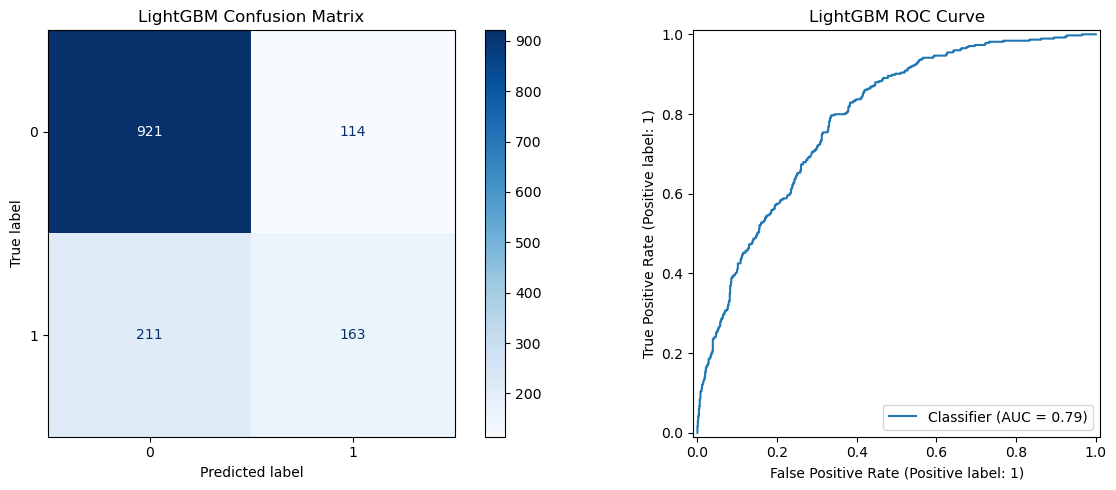

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=axes[0], cmap="Blues"
)
axes[0].set_title("LightGBM Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test, y_prob, ax=axes[1]
)
axes[1].set_title("LightGBM ROC Curve")

plt.tight_layout()
plt.show()

### Save the trained model and metrics

In [21]:
from pathlib import Path

# Create the folder to save model files
output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output directory:", output_dir.resolve())

Output directory: C:\CHURNIQ\MODELS


In [22]:
joblib.dump(
    lightgbm_pipeline,
    output_dir / "churniq_lightgbm_pipeline.joblib"
)

metrics = pd.DataFrame([{
    "model": "LightGBM",
    "roc_auc": roc_auc_score(y_test, y_prob),
    "average_precision": average_precision_score(y_test, y_prob)
}])

metrics.to_csv(
    output_dir / "lightgbm_metrics.csv",
    index=False
)

print("Model and metrics saved.")
display(metrics)

Model and metrics saved.


,model,roc_auc,average_precision
0,LightGBM,0.789802,0.567919


In [23]:
# verify saved files
print("Pipeline exists:",
      (output_dir / "churniq_lightgbm_pipeline.joblib").exists())

print("Metrics exist:",
      (output_dir / "lightgbm_metrics.csv").exists())

Pipeline exists: True
Metrics exist: True
